In [1]:
import os

# Kaggle usually extracts/mounts uploaded datasets under /kaggle/input/<dataset-name>/
base_path = "/kaggle/input/datasets/ashwinialashetty/figshare"
for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 3:  # don't spam deep file lists
        for f in files[:5]:
            print(f"{indent}  {f}")
        if len(files) > 5:
            print(f"{indent}  ... ({len(files)} files total)")

figshare/
  README 2024.txt
  cvind.mat
  brainTumorDataPublic_1-766/
    101.mat
    296.mat
    124.mat
    145.mat
    655.mat
    ... (766 files total)
  brainTumorDataPublic_2299-3064/
    2912.mat
    3027.mat
    3023.mat
    2911.mat
    2541.mat
    ... (766 files total)
  brainTumorDataPublic_1533-2298/
    2011.mat
    1912.mat
    2106.mat
    1850.mat
    1731.mat
    ... (766 files total)
  brainTumorDataPublic_767-1532/
    1194.mat
    851.mat
    1014.mat
    1082.mat
    1102.mat
    ... (766 files total)


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/ashwinialashetty/figshare"):
    for f in files:
        if f.endswith(".mat") and f != "cvind.mat":
            print(os.path.join(root, f))
            break  # just print one example per folder

/kaggle/input/datasets/ashwinialashetty/figshare/brainTumorDataPublic_1-766/101.mat
/kaggle/input/datasets/ashwinialashetty/figshare/brainTumorDataPublic_2299-3064/2912.mat
/kaggle/input/datasets/ashwinialashetty/figshare/brainTumorDataPublic_1533-2298/2011.mat
/kaggle/input/datasets/ashwinialashetty/figshare/brainTumorDataPublic_767-1532/1194.mat


In [6]:
import h5py

path = "/kaggle/input/datasets/ashwinialashetty/figshare/brainTumorDataPublic_1-766/101.mat"

with h5py.File(path, 'r') as f:
    print("Top-level keys:", list(f.keys()))
    cjdata = f['cjdata']
    print("cjdata fields:", list(cjdata.keys()))
    
    label = cjdata['label'][()]
    image = cjdata['image'][()]
    
    print("label:", label)
    print("image shape:", image.shape, "dtype:", image.dtype)
    print("image min/max:", image.min(), image.max())

Top-level keys: ['cjdata']
cjdata fields: ['PID', 'image', 'label', 'tumorBorder', 'tumorMask']
label: [[1.]]
image shape: (512, 512) dtype: int16
image min/max: 0 4814


In [7]:
import os
import glob
import h5py
import pandas as pd
from tqdm import tqdm

DATA_ROOT = "/kaggle/input/datasets/ashwinialashetty/figshare"

mat_files = sorted(glob.glob(os.path.join(DATA_ROOT, "brainTumorDataPublic_*", "*.mat")))
print(f"Found {len(mat_files)} .mat files")

records = []
for fp in tqdm(mat_files):
    with h5py.File(fp, 'r') as f:
        cjdata = f['cjdata']
        label = int(cjdata['label'][()][0, 0])   # 1, 2, or 3
        pid = cjdata['PID'][()]
        # PID can be stored as char codes; decode safely
        try:
            pid = ''.join(chr(c[0]) for c in pid)
        except Exception:
            pid = str(pid)
    records.append({"filepath": fp, "label": label, "pid": pid})

manifest = pd.DataFrame(records)

# Map numeric labels to names matching the paper
label_map = {1: "meningioma", 2: "glioma", 3: "pituitary"}
manifest["class_name"] = manifest["label"].map(label_map)

print(manifest["class_name"].value_counts())
manifest.to_csv("/kaggle/working/manifest.csv", index=False)

print("Saved manifest to /kaggle/working/manifest.csv")

Found 3064 .mat files


100%|██████████| 3064/3064 [00:17<00:00, 175.05it/s]

class_name
glioma        1426
pituitary      930
meningioma     708
Name: count, dtype: int64
Saved manifest to /kaggle/working/manifest.csv


In [8]:
import numpy as np
from sklearn.model_selection import train_test_split

manifest = pd.read_csv("/kaggle/working/manifest.csv")

# First split off the test set (10%), then split remaining into train/val (80/10 of total)
train_val, test = train_test_split(
    manifest, test_size=0.10, stratify=manifest["label"], random_state=42
)
train, val = train_test_split(
    train_val, test_size=(0.10 / 0.90), stratify=train_val["label"], random_state=42
)

print("Train:", len(train), train["class_name"].value_counts().to_dict())
print("Val:  ", len(val),   val["class_name"].value_counts().to_dict())
print("Test: ", len(test),  test["class_name"].value_counts().to_dict())

train.to_csv("/kaggle/working/train.csv", index=False)
val.to_csv("/kaggle/working/val.csv", index=False)
test.to_csv("/kaggle/working/test.csv", index=False)

Train: 2450 {'glioma': 1140, 'pituitary': 744, 'meningioma': 566}
Val:   307 {'glioma': 143, 'pituitary': 93, 'meningioma': 71}
Test:  307 {'glioma': 143, 'pituitary': 93, 'meningioma': 71}


In [9]:
import torch
from torch.utils.data import Dataset
import h5py
import numpy as np
import cv2

class FigshareBrainTumorDataset(Dataset):
    def __init__(self, dataframe, img_size=224, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_size = img_size
        self.transform = transform
        # labels in the .mat files are 1,2,3 -> remap to 0,1,2 for CrossEntropyLoss
        self.label_remap = {1: 0, 2: 1, 3: 2}  # meningioma, glioma, pituitary

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with h5py.File(row["filepath"], 'r') as f:
            image = f['cjdata']['image'][()]  # (512, 512), int16

        # normalize to 0-255 uint8
        image = image.astype(np.float32)
        image = (image - image.min()) / (image.max() - image.min() + 1e-8)
        image = (image * 255).astype(np.uint8)

        # resize to backbone input size
        image = cv2.resize(image, (self.img_size, self.img_size))

        # grayscale -> 3-channel (stack same channel 3x)
        image = np.stack([image, image, image], axis=-1)  # (H, W, 3)


        label = self.label_remap[int(row["label"])]

        if self.transform:
            image = self.transform(image)
        else:
            image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        return image, label

## **Step 5: DataLoaders + transforms + visual sanity check**

Train batches: 77, Val batches: 10, Test batches: 10
Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Unique labels in batch: tensor([0, 1, 2])


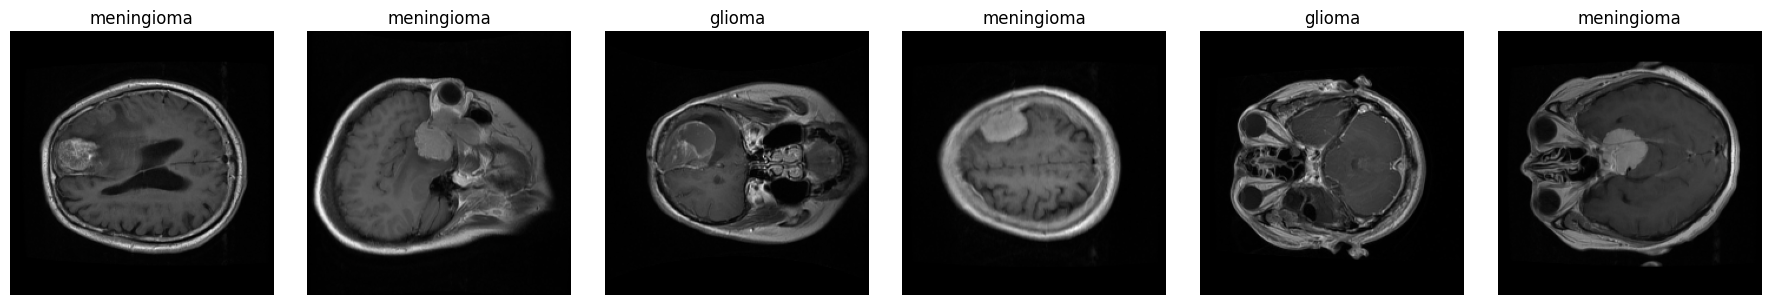

In [10]:
import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt

IMG_SIZE = 224
BATCH_SIZE = 32  # matches paper's Section 3.6

# ImageNet normalization since we'll use pretrained VGG16/ResNet50 weights
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

train_ds = FigshareBrainTumorDataset(train, img_size=IMG_SIZE, transform=train_transform)
val_ds   = FigshareBrainTumorDataset(val,   img_size=IMG_SIZE, transform=eval_transform)
test_ds  = FigshareBrainTumorDataset(test,  img_size=IMG_SIZE, transform=eval_transform)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = torch.utils.data.DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

# Sanity check: pull one batch and inspect shapes

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)   # expect (32, 3, 224, 224)
print("Batch label shape:", labels.shape)
print("Unique labels in batch:", labels.unique())

# Visual check: un-normalize and plot a few samples
class_names = ["meningioma", "glioma", "pituitary"]

def denormalize(img_tensor):
    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std = torch.tensor(imagenet_std).view(3, 1, 1)
    return (img_tensor * std + mean).clamp(0, 1)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for i in range(6):
    img = denormalize(images[i]).permute(1, 2, 0).numpy()
    axes[i].imshow(img)
    axes[i].set_title(class_names[labels[i].item()])
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## Step 6: Build the ResNet50 + SSPANet classifier

In [11]:
import torch
import torch.nn as nn


class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction_kernel=1):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.conv = nn.Conv2d(2, 1, kernel_size=reduction_kernel, padding=reduction_kernel // 2, bias=False)
        self.bn = nn.BatchNorm2d(1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.avg_pool(x).squeeze(-1).squeeze(-1)
        mx = self.max_pool(x).squeeze(-1).squeeze(-1)
        z = torch.stack([avg, mx], dim=1).unsqueeze(-1)
        f1 = self.bn(self.conv(z))
        m_c = self.sigmoid(f1).squeeze(1).squeeze(-1)
        return m_c.view(m_c.size(0), m_c.size(1), 1, 1)


class StripAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))
        self.conv = nn.Conv2d(in_channels, in_channels, kernel_size=1, bias=False)

    def forward(self, x):
        b, c, h, w = x.shape
        s_h = self.pool_h(x).expand(-1, -1, -1, w)

        s_v = self.pool_w(x).expand(-1, -1, h, -1)
        return self.conv(s_h + s_v)


class StyleAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.conv = nn.Conv2d(2, in_channels, kernel_size=1, bias=False)

    def forward(self, x):
        mu = x.mean(dim=1, keepdim=True)
        sigma = x.std(dim=1, keepdim=True, unbiased=False)
        return self.conv(torch.cat([mu, sigma], dim=1))


class SpatialAttention(nn.Module):
    def __init__(self, in_channels, use_strip=True, use_style=True):
        super().__init__()
        assert use_strip or use_style
        self.use_strip, self.use_style = use_strip, use_style
        if use_strip: self.strip = StripAttention(in_channels)
        if use_style: self.style = StyleAttention(in_channels)
        self.fuse_conv = nn.Conv2d(in_channels, 1, kernel_size=1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        if self.use_strip and self.use_style:
            fused = self.strip(x) + self.style(x)
        elif self.use_strip:
            fused = self.strip(x)
        else:
            fused = self.style(x)

        return self.sigmoid(self.fuse_conv(fused))


class SSPANet(nn.Module):
    def __init__(self, in_channels, use_channel=True, use_strip=True, use_style=True, residual=True):
        super().__init__()
        self.use_channel = use_channel
        self.residual = residual
        if use_channel:
            self.channel_attn = ChannelAttention(in_channels)
        self.use_spatial = use_strip or use_style
        if self.use_spatial:
            self.spatial_attn = SpatialAttention(in_channels, use_strip, use_style)

    def forward(self, x):
        out = x
        if self.use_channel:
            out = out * self.channel_attn(out)
        if self.use_spatial:
            out = out * self.spatial_attn(out)
        if self.residual:
            out = out + x
        return out

In [12]:
import torchvision.models as models

class ResNetSSPANet(nn.Module):
    def __init__(self, num_classes=3, use_channel=True, use_strip=True, use_style=True, pretrained=True):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)

        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1   # 256 channels
        self.layer2 = resnet.layer2   # 512 channels
        self.layer3 = resnet.layer3   # 1024 channels
        self.layer4 = resnet.layer4   # 2048 channels

        attn_kwargs = dict(use_channel=use_channel, use_strip=use_strip, use_style=use_style)
        self.attn1 = SSPANet(256,  **attn_kwargs)
        self.attn2 = SSPANet(512,  **attn_kwargs)
        self.attn3 = SSPANet(1024, **attn_kwargs)
        self.attn4 = SSPANet(2048, **attn_kwargs)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.attn1(self.layer1(x))
        x = self.attn2(self.layer2(x))
        x = self.attn3(self.layer3(x))
        x = self.attn4(self.layer4(x))
        x = self.avgpool(x).flatten(1)
        return self.fc(x)



# quick sanity check
model = ResNetSSPANet(num_classes=3).cuda() if torch.cuda.is_available() else ResNetSSPANet(num_classes=3)
device = next(model.parameters()).device
print("Model on:", device)

dummy = images[:2].to(device)
out = model(dummy)
print("Output shape:", out.shape)  # expect (2, 3)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 233MB/s]


Model on: cuda:0
Output shape: torch.Size([2, 3])


# Step 7: Training loop matching the paper’s experimental settings (Section 3.6)

In [13]:
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score, matthews_corrcoef
import numpy as np
import time

def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)

            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="macro", zero_division=0)
    kappa = cohen_kappa_score(all_labels, all_preds)
    mcc = matthews_corrcoef(all_labels, all_preds)

    return {
        "loss": avg_loss, "accuracy": acc, "precision": precision,
        "recall": recall, "f1": f1, "kappa": kappa, "mcc": mcc

    }


def train_model(model, train_loader, val_loader, device, epochs=30, lr=0.0001, patience=7, model_name="model"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float("inf")
    patience_counter = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        all_preds, all_labels = [], []
        t0 = time.time()

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())


        train_loss = running_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_labels, all_preds)

        val_metrics = evaluate(model, val_loader, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["accuracy"])

        elapsed = time.time() - t0
        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} | "
              f"{elapsed:.1f}s")

        # early stopping on val loss (matches paper's Section 3.6)
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            patience_counter = 0
            torch.save(model.state_dict(), f"/kaggle/working/{model_name}_best.pt")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    # reload best weights
    model.load_state_dict(torch.load(f"/kaggle/working/{model_name}_best.pt"))
    return model, history

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = ResNetSSPANet(num_classes=3).to(device)

model, history = train_model(
    model, train_loader, val_loader, device,
    epochs=2, lr=0.0001, patience=7, model_name="resnet_sspanet_sanity"
)

[resnet_sspanet_sanity] Epoch 1/2 | train_loss=0.3616 train_acc=0.8739 | val_loss=0.2480 val_acc=0.9023 | 37.9s
[resnet_sspanet_sanity] Epoch 2/2 | train_loss=0.0659 train_acc=0.9804 | val_loss=0.1330 val_acc=0.9609 | 39.6s


## Step 8: Run the full 30-epoch training (matching the paper’s Table 3 setup: ResNet50 + SSPANet)

In [15]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model_full = ResNetSSPANet(num_classes=3).to(device)

model_full, history_full = train_model(
    model_full, train_loader, val_loader, device,
    epochs=30, lr=0.0001, patience=7, model_name="resnet_sspanet_full"
)

[resnet_sspanet_full] Epoch 1/30 | train_loss=0.3543 train_acc=0.8592 | val_loss=0.1771 val_acc=0.9251 | 43.2s
[resnet_sspanet_full] Epoch 2/30 | train_loss=0.0619 train_acc=0.9788 | val_loss=0.1002 val_acc=0.9479 | 41.3s
[resnet_sspanet_full] Epoch 3/30 | train_loss=0.0254 train_acc=0.9918 | val_loss=0.1110 val_acc=0.9642 | 42.7s
[resnet_sspanet_full] Epoch 4/30 | train_loss=0.0225 train_acc=0.9931 | val_loss=0.1318 val_acc=0.9674 | 41.6s
[resnet_sspanet_full] Epoch 5/30 | train_loss=0.0120 train_acc=0.9967 | val_loss=0.1281 val_acc=0.9544 | 42.0s
[resnet_sspanet_full] Epoch 6/30 | train_loss=0.0095 train_acc=0.9976 | val_loss=0.1314 val_acc=0.9642 | 41.8s
[resnet_sspanet_full] Epoch 7/30 | train_loss=0.0049 train_acc=0.9988 | val_loss=0.1731 val_acc=0.9577 | 42.0s
[resnet_sspanet_full] Epoch 8/30 | train_loss=0.0054 train_acc=0.9980 | val_loss=0.1296 val_acc=0.9674 | 42.0s
[resnet_sspanet_full] Epoch 9/30 | train_loss=0.0033 train_acc=0.9992 | val_loss=0.1717 val_acc=0.9414 | 41.9s
E

## Step 9: Evaluate on test set first (to see where we actually stand), then fix overfitting

In [16]:
test_metrics = evaluate(model_full, test_loader, device)
print("Test set results (ResNet50 + SSPANet):")
for k, v in test_metrics.items():
    print(f"  {k}: {v:.4f}")

Test set results (ResNet50 + SSPANet):
  loss: 0.1176
  accuracy: 0.9577
  precision: 0.9545
  recall: 0.9484
  f1: 0.9509
  kappa: 0.9334
  mcc: 0.9338


In [17]:
train_transform_aug = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

train_ds_aug = FigshareBrainTumorDataset(train, img_size=IMG_SIZE, transform=train_transform_aug)
train_loader_aug = torch.utils.data.DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

# Step 10: Rerun with augmentation + longer patience

In [18]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model_aug = ResNetSSPANet(num_classes=3).to(device)

model_aug, history_aug = train_model(
    model_aug, train_loader_aug, val_loader, device,
    epochs=30, lr=0.0001, patience=12, model_name="resnet_sspanet_aug"
)

[resnet_sspanet_aug] Epoch 1/30 | train_loss=0.4394 train_acc=0.8306 | val_loss=0.1719 val_acc=0.9316 | 42.9s
[resnet_sspanet_aug] Epoch 2/30 | train_loss=0.1426 train_acc=0.9453 | val_loss=0.1284 val_acc=0.9577 | 41.5s
[resnet_sspanet_aug] Epoch 3/30 | train_loss=0.0910 train_acc=0.9678 | val_loss=0.1035 val_acc=0.9707 | 42.6s
[resnet_sspanet_aug] Epoch 4/30 | train_loss=0.0703 train_acc=0.9759 | val_loss=0.1170 val_acc=0.9674 | 41.6s
[resnet_sspanet_aug] Epoch 5/30 | train_loss=0.0443 train_acc=0.9837 | val_loss=0.0697 val_acc=0.9772 | 42.2s
[resnet_sspanet_aug] Epoch 6/30 | train_loss=0.0372 train_acc=0.9878 | val_loss=0.0394 val_acc=0.9870 | 42.1s
[resnet_sspanet_aug] Epoch 7/30 | train_loss=0.0227 train_acc=0.9935 | val_loss=0.0560 val_acc=0.9837 | 41.8s
[resnet_sspanet_aug] Epoch 8/30 | train_loss=0.0273 train_acc=0.9902 | val_loss=0.0784 val_acc=0.9772 | 42.0s
[resnet_sspanet_aug] Epoch 9/30 | train_loss=0.0274 train_acc=0.9890 | val_loss=0.0425 val_acc=0.9870 | 41.9s
[resnet_ss

In [19]:
test_metrics_aug = evaluate(model_aug, test_loader, device)
print("Test set results (ResNet50 + SSPANet, with augmentation):")
for k, v in test_metrics_aug.items():
    print(f"  {k}: {v:.4f}")

Test set results (ResNet50 + SSPANet, with augmentation):
  loss: 0.0638
  accuracy: 0.9837
  precision: 0.9791
  recall: 0.9836
  f1: 0.9813
  kappa: 0.9745
  mcc: 0.9747


## Step 12: Ablation study — isolate each sub-component’s contribution

In [20]:
ablation_configs = {
    "channel_only":  dict(use_channel=True,  use_strip=False, use_style=False),
    "strip_only":    dict(use_channel=False, use_strip=True,  use_style=False),
    "style_only":    dict(use_channel=False, use_strip=False, use_style=True),
    "full_sspanet":  dict(use_channel=True,  use_strip=True,  use_style=True),
}

ablation_results = {}

for name, cfg in ablation_configs.items():
    print(f"\n{'='*20} Training: {name} {'='*20}")
    m = ResNetSSPANet(num_classes=3, **cfg).to(device)
    m, hist = train_model(
        m, train_loader_aug, val_loader, device,
        epochs=30, lr=0.0001, patience=10, model_name=f"ablation_{name}"
    )
    test_res = evaluate(m, test_loader, device)
    ablation_results[name] = test_res
    print(f"[{name}] TEST → acc={test_res['accuracy']:.4f} f1={test_res['f1']:.4f} kappa={test_res['kappa']:.4f} mcc={test_res['mcc']:.4f}")

# summary table
ablation_df = pd.DataFrame(ablation_results).T
ablation_df = ablation_df[["accuracy", "precision", "recall", "f1", "kappa", "mcc"]]
print("\n=== Ablation Summary ===")
print(ablation_df.round(4))
ablation_df.to_csv("/kaggle/working/ablation_results.csv")


==================== Training: channel_only ====================
[ablation_channel_only] Epoch 1/30 | train_loss=0.4222 train_acc=0.8282 | val_loss=0.1963 val_acc=0.9153 | 42.6s
[ablation_channel_only] Epoch 2/30 | train_loss=0.1660 train_acc=0.9359 | val_loss=0.1432 val_acc=0.9544 | 39.6s
[ablation_channel_only] Epoch 3/30 | train_loss=0.0869 train_acc=0.9702 | val_loss=0.0943 val_acc=0.9609 | 34.2s
[ablation_channel_only] Epoch 4/30 | train_loss=0.0648 train_acc=0.9784 | val_loss=0.1589 val_acc=0.9511 | 33.7s
[ablation_channel_only] Epoch 5/30 | train_loss=0.0418 train_acc=0.9878 | val_loss=0.1050 val_acc=0.9577 | 33.5s
[ablation_channel_only] Epoch 6/30 | train_loss=0.0327 train_acc=0.9906 | val_loss=0.1415 val_acc=0.9479 | 33.2s
[ablation_channel_only] Epoch 7/30 | train_loss=0.0335 train_acc=0.9894 | val_loss=0.0897 val_acc=0.9577 | 33.2s
[ablation_channel_only] Epoch 8/30 | train_loss=0.0238 train_acc=0.9918 | val_loss=0.1107 val_acc=0.9609 | 33.5s
[ablation_channel_only] Epoch 

## Step 13: Seed-controlled reruns

In [1]:
from torch.cuda.amp import autocast, GradScaler
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def train_model_fast(model, train_loader, val_loader, device, epochs=20, lr=0.0001, patience=7, model_name="model"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scaler = GradScaler()

    best_val_loss = float("inf")
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        all_preds, all_labels = [], []
        t0 = time.time()

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)

            scaler.update()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_labels, all_preds)
        val_metrics = evaluate(model, val_loader, device)

        elapsed = time.time() - t0
        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} | {elapsed:.1f}s")

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            patience_counter = 0
            torch.save(model.state_dict(), f"/kaggle/working/{model_name}_best.pt")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(f"/kaggle/working/{model_name}_best.pt"))
    return model


seed_results = {}
configs_to_verify = {
    "channel_only": dict(use_channel=True, use_strip=False, use_style=False),
    "full_sspanet": dict(use_channel=True, use_strip=True, use_style=True),

}
seeds = [123, 456]

for config_name, cfg in configs_to_verify.items():
    for seed in seeds:
        run_name = f"{config_name}_seed{seed}"
        print(f"\n{'='*15} {run_name} {'='*15}")
        set_seed(seed)
        m = ResNetSSPANet(num_classes=3, **cfg).to(device)
        m = train_model_fast(m, train_loader_aug, val_loader, device, epochs=20, patience=7, model_name=run_name)
        test_res = evaluate(m, test_loader, device)
        seed_results[run_name] = test_res
        print(f"[{run_name}] TEST → acc={test_res['accuracy']:.4f} f1={test_res['f1']:.4f}")

seed_df = pd.DataFrame(seed_results).T[["accuracy", "precision", "recall", "f1", "kappa", "mcc"]]
print("\n=== Multi-seed Verification ===")
print(seed_df.round(4))
seed_df.to_csv("/kaggle/working/multiseed_results.csv")


=============== channel_only_seed123 ===============


NameError: name 'np' is not defined